**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Aarón Hernández Jiménez
*   MATRÍCULA: A01642529

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

# Diagnose_MV_Numerical (función del curso) usa plt.boxplot(..., vert=False) y matplotlib >= 3.10 avisa
# que vert será reemplazado por orientation. Se oculta solo ese aviso porque no afecta los resultados.
warnings.filterwarnings('ignore', message='vert: bool')

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [2]:
cardio_df = pd.read_csv('heart_disease.csv', index_col='id')
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


In [3]:
cardio_df.nunique()

age          50
sex           2
origin        4
cp            4
trestbps     60
chol        216
fbs           2
restecg       3
thalch      119
exang         2
oldpeak      53
slope         3
ca            4
thal          3
num           5
dtype: int64

Respuesta:

El dataframe tiene 918 registros y 15 columnas (sin contar el id). Según info() hay 7 columnas numéricas (age, trestbps, chol, thalch, oldpeak, ca y num) y 8 de texto (sex, origin, cp, fbs, restecg, exang, slope y thal). fbs y exang en realidad son True/False, pero pandas las lee como texto porque tienen faltantes.

En valores únicos, las categóricas tienen entre 2 y 5, mientras que las continuas tienen muchos más, desde 50 en age hasta 216 en chol.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [4]:
cardio_df.select_dtypes(include='number').nunique().sort_values()

ca            4
num           5
age          50
oldpeak      53
trestbps     60
thalch      119
chol        216
dtype: int64

In [5]:
# ca y num son ordinales: se convierten a categóricas indicando el orden de sus niveles
cardio_df['ca'] = pd.Categorical(cardio_df['ca'], categories=[0, 1, 2, 3], ordered=True)
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)
cardio_df['ca'].dtype, cardio_df['num'].dtype

(CategoricalDtype(categories=[0, 1, 2, 3], ordered=True, categories_dtype=int64),
 CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True, categories_dtype=int64))

Respuesta:

ca (4 valores) y num (5 valores) están como numéricas, pero en realidad son categóricas. Las dos son ordinales: ca es el número de vasos coloreados (0 a 3), y entre más vasos peor, y num es el grado de enfermedad (0 sano, 1 a 4 cada vez más grave). Por eso se convirtieron a categóricas con orden 0 < 1 < 2 < 3 y 0 < 1 < 2 < 3 < 4. Las demás numéricas son continuas y se quedan igual.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [6]:
num_cols = cardio_df.select_dtypes(include='number').columns
desc_num = cardio_df[num_cols].describe().T
desc_num['sesgo'] = cardio_df[num_cols].skew()
desc_num['curtosis'] = cardio_df[num_cols].kurt()
desc_num

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


In [7]:
cardio_df.describe(exclude='number').T

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309,4,0,181
thal,434,3,normal,196
num,918,5,0,411


In [8]:
for col in cardio_df.select_dtypes(exclude='number').columns:
    display(cardio_df[col].value_counts(dropna=False).to_frame())

,count
sex,
Male,724
Female,194


,count
origin,
Cleveland,304
Hungary,292
VA Long Beach,200
Switzerland,122


,count
cp,
asymptomatic,495
non-anginal,204
atypical angina,174
typical angina,45


,count
fbs,
False,691
True,138
NaN,89


,count
restecg,
normal,551
lv hypertrophy,188
st-t abnormality,179


,count
exang,
False,526
True,337
NaN,55


,count
slope,
flat,345
NaN,308
upsloping,202
downsloping,63


,count
ca,
NaN,609
0,181
1,67
2,41
3,20


,count
thal,
NaN,484
normal,196
reversable defect,192
fixed defect,46


,count
num,
0,411
1,263
2,109
3,107
4,28


In [9]:
# chol: valores más repetidos y origen de los pacientes con el valor más frecuente
display(cardio_df['chol'].value_counts().head(3).to_frame())
cardio_df.loc[cardio_df['chol'] == 223, 'origin'].value_counts()

,count
chol,
223.0,180
220.0,10
254.0,10


origin
Switzerland      122
VA Long Beach     52
Cleveland          3
Hungary            3
Name: count, dtype: int64

Respuesta:

Numéricas: age y thalch son casi simétricas (sesgo cercano a 0). trestbps y oldpeak tienen cola a la derecha (sesgo 0.63 y 1.04). chol es la más sesgada (1.64) y tiene una curtosis muy alta (6.57), porque 180 pacientes tienen exactamente 223, que es la mediana, casi todos de Switzerland y VA Long Beach. Parece que esos datos ya venían rellenados con un valor fijo.

Categóricas: la mayoría son hombres (724 de 918), el dolor más común es asymptomatic (495) y en restecg predomina normal (551). En fbs y exang predomina False. slope, thal y ca tienen muchos faltantes. En num hay 411 sanos y 507 con algún grado de enfermedad, aunque los grados 3 y 4 son pocos.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [10]:
pct_mv = (cardio_df.isna().mean() * 100).sort_values(ascending=False)
pct_mv.round(2)

ca          66.34
thal        52.72
slope       33.55
fbs          9.69
oldpeak      6.75
trestbps     6.43
thalch       5.99
exang        5.99
chol         3.27
age          0.00
sex          0.00
origin       0.00
cp           0.00
restecg      0.00
num          0.00
dtype: float64

In [11]:
cols_drop = pct_mv[pct_mv > 30].index
cardio_df = cardio_df.drop(columns=cols_drop)
print('Columnas eliminadas:', list(cols_drop))

Columnas eliminadas: ['ca', 'thal', 'slope']


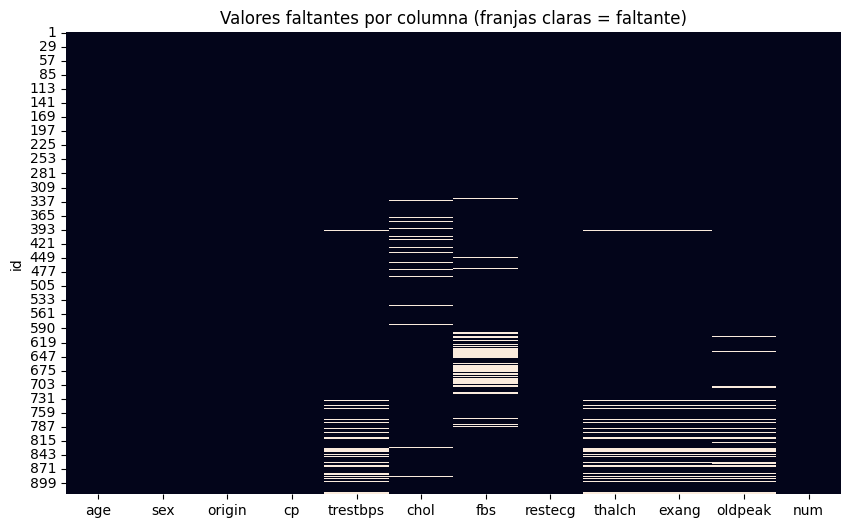

In [12]:
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isna(), cbar=False)
plt.title('Valores faltantes por columna (franjas claras = faltante)')
plt.ylabel('id')
plt.show()

In [13]:
# Pacientes sin thalch: qué otras columnas les faltan
BM_MV = cardio_df['thalch'].isna()
display(cardio_df[BM_MV].isna().sum().to_frame('faltantes cuando falta thalch'))

# Faltantes por centro de origen
cardio_df.isna().groupby(cardio_df['origin']).sum()

,faltantes cuando falta thalch
age,0
sex,0
origin,0
cp,0
trestbps,55
chol,3
fbs,0
restecg,0
thalch,55
exang,55


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
origin,,,,,,,,,,,,
Cleveland,0,0,0,0,0,0,0,0,0,0,0,0
Hungary,0,0,0,0,1,23,8,0,1,1,0,0
Switzerland,0,0,0,0,2,0,74,0,1,1,6,0
VA Long Beach,0,0,0,0,56,7,7,0,53,53,56,0


Respuesta:

Se eliminaron ca (66.3%), thal (52.7%) y slope (33.6%) por tener más del 30% de faltantes. Siguen con faltantes fbs, oldpeak, trestbps, thalch, exang y chol, todas con menos del 10%.

En el mapa de calor se ve que trestbps, thalch, exang y oldpeak faltan al mismo tiempo en las mismas filas, sobre todo al final del dataset. De los 55 pacientes sin thalch, a todos les falta también exang y trestbps, a 54 les falta oldpeak, y casi todos son de VA Long Beach.

Tiene sentido médico porque thalch, exang y oldpeak salen de la misma prueba de esfuerzo, así que si no se hizo la prueba faltan los tres. trestbps es la presión en reposo, y la prueba de esfuerzo empieza midiendo justo eso, por eso también falta. Como casi todo viene de un solo hospital, lo más probable es que ahí no se registraban esos datos.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [14]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [15]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

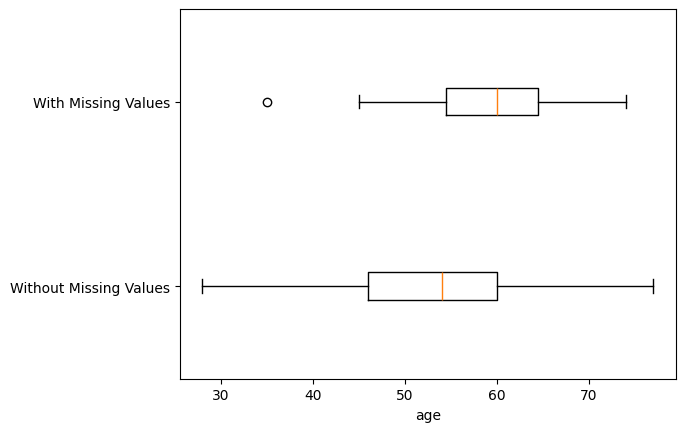

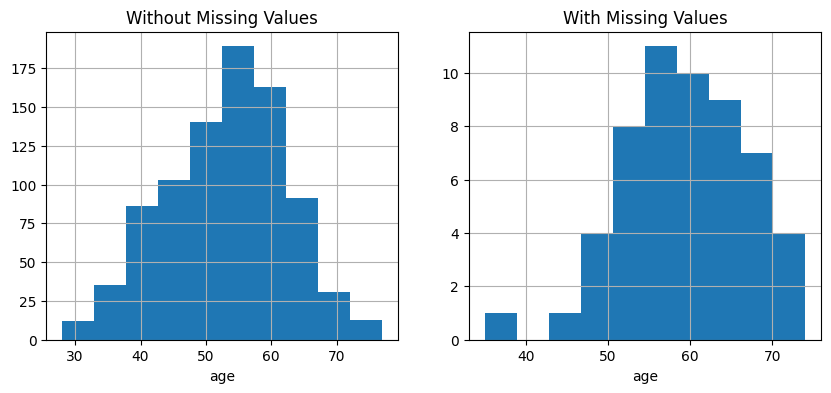

p-value of t-test: 1.5041244185890902e-06


In [16]:
BM_MV = cardio_df['thalch'].isna()
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV)

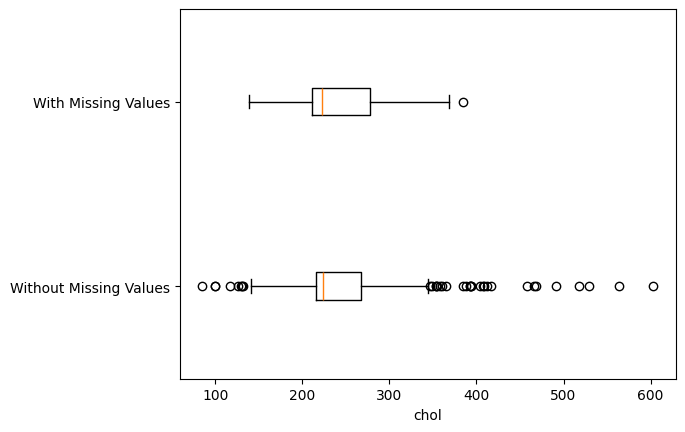

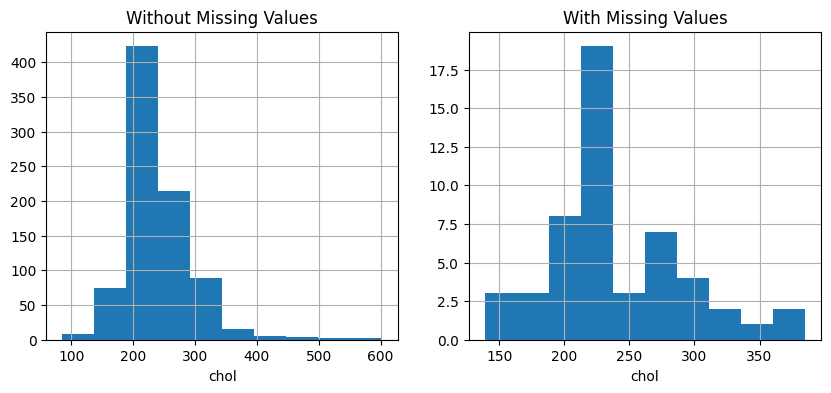

p-value of t-test: 0.7165289974295672


In [17]:
Diagnose_MV_Numerical(cardio_df, 'chol', BM_MV)

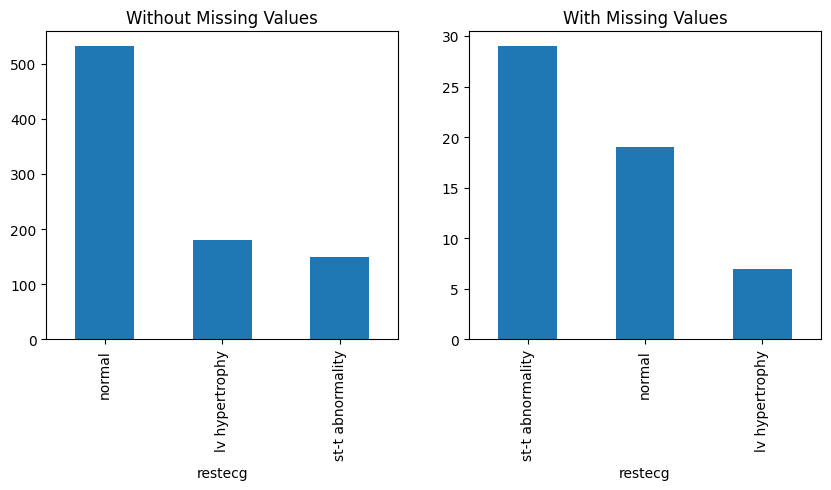

p-value of Chi_squared test: 1.1472889573985467e-09


In [18]:
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV)

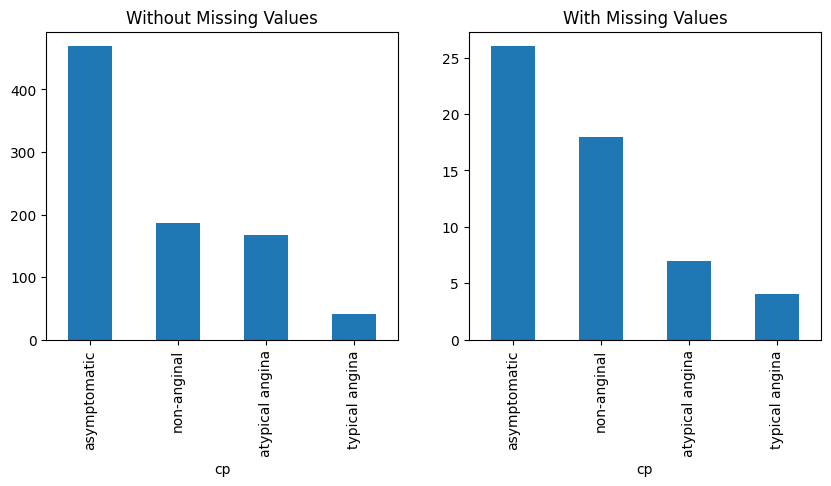

p-value of Chi_squared test: 0.1542009717725172


In [19]:
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV)

In [20]:
# Medias y proporciones por grupo (True = falta thalch) para apoyar las conclusiones
display(cardio_df.groupby(BM_MV)[['age', 'chol']].mean().round(1))
display(pd.crosstab(BM_MV, cardio_df['restecg'], normalize='index').round(3))
pd.crosstab(BM_MV, cardio_df['cp'], normalize='index').round(3)

,age,chol
thalch,,
False,53.2,242.4
True,59.4,239.6


restecg,lv hypertrophy,normal,st-t abnormality
thalch,,,
False,0.210,0.616,0.174
True,0.127,0.345,0.527


cp,asymptomatic,atypical angina,non-anginal,typical angina
thalch,,,,
False,0.543,0.194,0.216,0.048
True,0.473,0.127,0.327,0.073


Respuesta:

Resultados de las pruebas (alfa = 0.05):

- age: p ≈ 1.5e-06, sí hay diferencia. Los pacientes sin thalch son mayores (59.4 años contra 53.2).
- chol: p ≈ 0.72, no hay diferencia, las gráficas de los dos grupos se ven casi iguales.
- restecg: p ≈ 1.1e-09, sí hay diferencia. En el grupo con faltantes predomina st-t abnormality (53%) y en el otro predomina normal (62%).
- cp: p ≈ 0.15, no hay diferencia, en los dos grupos predomina asymptomatic.

Conclusión: los faltantes de thalch no son completamente al azar, dependen de la edad y del resultado del ECG en reposo, que son variables que sí tenemos. Por eso el mecanismo es MAR y no MCAR. Tiene sentido porque a pacientes mayores o con alteraciones en el ECG es más probable que no se les haga la prueba de esfuerzo. Lo mismo aplica para exang, oldpeak y trestbps, porque tienen el mismo patrón.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [21]:
# Medianas de cada grupo de restecg (las que se usan para imputar las numéricas)
display(cardio_df.groupby('restecg')[['thalch', 'trestbps', 'oldpeak']].median())

for col in ['thalch', 'trestbps', 'oldpeak']:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))

# exang no es numérica (True / False), así que se usa la moda de cada grupo.
# Antes se pasa a tipo boolean, porque pandas la leyó como object por tener faltantes.
cardio_df['exang'] = cardio_df['exang'].astype('boolean')
cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(x.mode()[0]))

cardio_df[['thalch', 'trestbps', 'oldpeak', 'exang']].isna().sum()

,thalch,trestbps,oldpeak
restecg,,,
lv hypertrophy,146.0,130.0,0.8
normal,140.0,130.0,0.2
st-t abnormality,129.0,130.0,0.9


thalch      0
trestbps    0
oldpeak     0
exang       0
dtype: int64

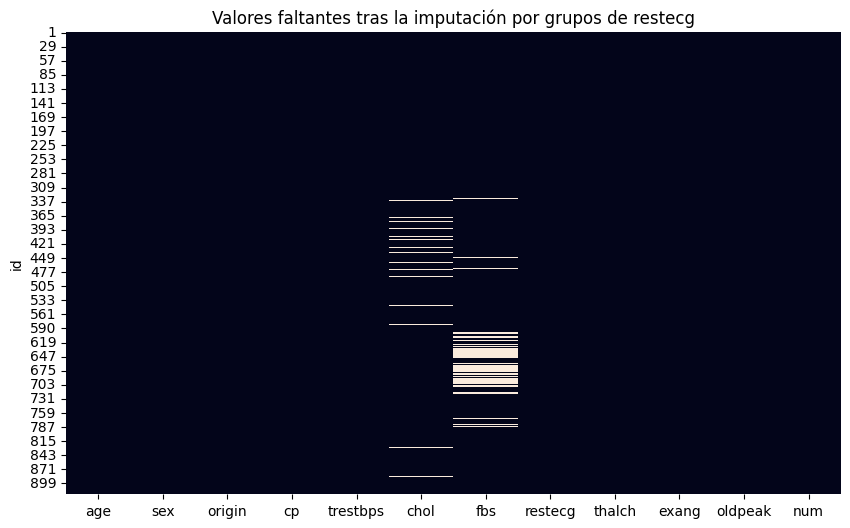

In [22]:
plt.figure(figsize=(10, 6))
sns.heatmap(cardio_df.isna(), cbar=False)
plt.title('Valores faltantes tras la imputación por grupos de restecg')
plt.ylabel('id')
plt.show()

Respuesta:

thalch, trestbps y oldpeak se imputaron con la mediana de cada grupo de restecg, porque la mediana no se ve afectada por los valores extremos. exang es True/False, así que ahí se usó la moda del grupo (antes se pasó a tipo boolean porque pandas la tenía como texto). Por ejemplo, a thalch se le pone 146, 140 o 129 según el grupo, en lugar de un solo valor para todos. En el nuevo mapa de calor esas cuatro columnas ya no tienen faltantes, solo quedan chol y fbs.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [23]:
faltantes = cardio_df.isna().sum()
faltantes[faltantes > 0]

chol    30
fbs     89
dtype: int64

In [24]:
imp_mediana = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_mediana.fit_transform(cardio_df[['chol']])

imp_moda = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imp_moda.fit_transform(cardio_df[['fbs']])

print('Faltantes totales:', cardio_df.isna().sum().sum())

Faltantes totales: 0


Respuesta:

Quedaban faltantes en chol (30) y fbs (89). Para chol se usó median porque es numérica y tiene valores muy altos (hasta 603) que suben la media (242) por encima de la mediana (223). Para fbs se usó most_frequent porque es True/False y no tiene sentido sacar media ni mediana, así que se rellena con False, que es lo más común. Al final ya no queda ningún faltante.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

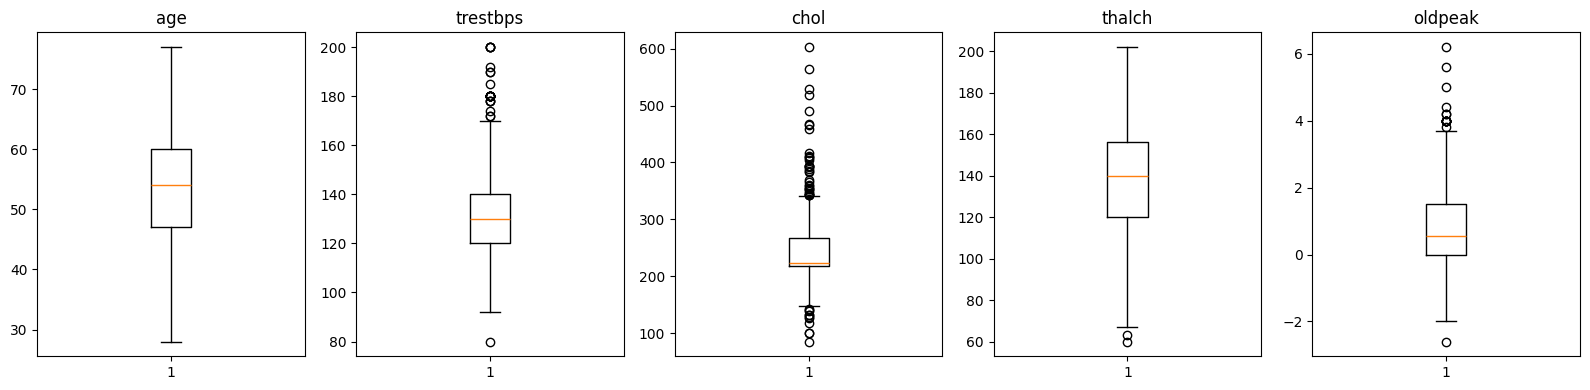

age: 0 atípicos -> []
trestbps: 27 atípicos -> [ 80. 172. 174. 178. 180. 185. 190. 192. 200.]
chol: 44 atípicos -> [ 85. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 344. 347. 349.
 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392. 393. 394. 404.
 407. 409. 412. 417. 458. 466. 468. 491. 518. 529. 564. 603.]
thalch: 2 atípicos -> [60. 63.]
oldpeak: 16 atípicos -> [-2.6  3.8  4.   4.2  4.4  5.   5.6  6.2]


In [25]:
num_cols = cardio_df.select_dtypes(include='number').columns
outliers_graf = {}

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(cardio_df[col])
    ax.set_title(col)
    outliers_graf[col] = bp['fliers'][0].get_ydata()
plt.tight_layout()
plt.show()

for col, vals in outliers_graf.items():
    print(f'{col}: {len(vals)} atípicos -> {np.unique(vals)}')

Respuesta:

Con los fliers del boxplot salieron estos atípicos: age ninguno, trestbps 27 (el 80 y valores de 172 a 200), chol 44 (bajos de 85 a 142 y altos de 342 a 603), thalch 2 (60 y 63) y oldpeak 16 (el -2.6 y valores de 3.8 a 6.2). chol tiene tantos porque muchos pacientes tienen 223 y eso hace la caja muy angosta.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [26]:
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR
print(f'Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}')
print(f'Límite inferior = {lim_inf}, límite superior = {lim_sup}')

BM_out = (cardio_df['trestbps'] < lim_inf) | (cardio_df['trestbps'] > lim_sup)
outliers_iqr = cardio_df.loc[BM_out, 'trestbps']
print(f'{len(outliers_iqr)} atípicos ->', np.sort(outliers_iqr.values))

print('¿Coinciden con el método gráfico?',
      np.array_equal(np.sort(outliers_iqr.values), np.sort(outliers_graf['trestbps'])))

Q1 = 120.0, Q3 = 140.0, IQR = 20.0
Límite inferior = 90.0, límite superior = 170.0
27 atípicos -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
¿Coinciden con el método gráfico? True


Respuesta:

Q1 = 120 y Q3 = 140, así que el IQR es 20, el límite inferior 90 y el superior 170. Quedan fuera 27 valores (el 80 y los de 172 a 200) y sí coinciden con los del boxplot, porque el boxplot usa la misma regla de 1.5 veces el IQR.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Registros restantes: 891


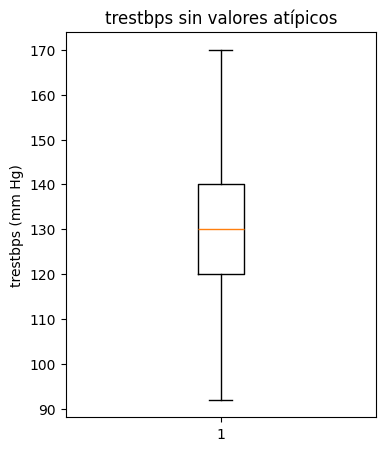

In [27]:
cardio_df = cardio_df[~BM_out]
print('Registros restantes:', cardio_df.shape[0])

plt.figure(figsize=(4, 5))
plt.boxplot(cardio_df['trestbps'])
plt.ylabel('trestbps (mm Hg)')
plt.title('trestbps sin valores atípicos')
plt.show()

Respuesta:

Se quitaron los 27 registros con trestbps atípico y quedaron 891. En el boxplot final los valores van de 92 a 170, con mediana de 130, y ya no hay puntos fuera de los bigotes.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude (Opus 5.5)* [Modelo de lenguaje grande], utilizado para edición de código, depuración y apoyo en la redacción correcta de los análisis. https://claude.ai/

---